# 1.Instalation and Data Preprocessing

In [ ]:

!pip install pyro-ppl

import torch
import pyro
import pyro.distributions as dist
from pyro.infer import MCMC, NUTS
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                           precision_score, recall_score, f1_score, roc_auc_score,
                           roc_curve, auc)
import seaborn as sns
import matplotlib.pyplot as plt

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
pyro.set_rng_seed(RANDOM_SEED)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 11.3 MB/s eta 0:00:00


##  Data Loading and Initial Split

In [ ]:
# Load data
data = pd.read_csv('processed_heart_data.csv')

# Split into two parts
split_index = int(len(data) * 0.2)
shuffled_data = data.sample(frac=1, random_state=42).reset_index(drop=True)
larger_dataset = shuffled_data.iloc[:split_index]
smaller_dataset = shuffled_data.iloc[split_index:]

print("Larger Dataset Shape:", larger_dataset.shape)
print("Smaller Dataset Shape:", smaller_dataset.shape)

Larger Dataset Shape: (183, 16)
Smaller Dataset Shape: (735, 16)


## Data Preparation and Scaling

In [ ]:

X = larger_dataset.drop('HeartDisease', axis=1)
y = larger_dataset['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)


numeric_features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
scaler = StandardScaler()
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])

print("Training Set Size:", X_train.shape)
print("Test Set Size:", X_test.shape)

Training Set Size: (137, 15)
Test Set Size: (46, 15)


# 2. Analysis on large dataset

## a. Initial Logistic Regression with All Features

In [ ]:

X_train_with_const = sm.add_constant(X_train)
initial_logit_model = sm.Logit(y_train, X_train_with_const)
initial_results = initial_logit_model.fit()

summary_df = pd.DataFrame({
    'Feature': initial_results.model.exog_names[1:],  # Exclude constant
    'Coefficient': initial_results.params[1:],
    'Std Error': initial_results.bse[1:],
    'z-value': initial_results.tvalues[1:],
    'p-value': initial_results.pvalues[1:],
    'CI Lower': initial_results.conf_int()[1:][0],
    'CI Upper': initial_results.conf_int()[1:][1]
})

numeric_columns = ['Coefficient', 'Std Error', 'z-value', 'p-value', 'CI Lower', 'CI Upper']
summary_df[numeric_columns] = summary_df[numeric_columns].round(4)

print("=== Complete Logistic Regression Summary ===")
print(initial_results.summary().as_text())

Optimization terminated successfully.
         Current function value: 0.226577
         Iterations 8
=== Complete Logistic Regression Summary ===
                           Logit Regression Results                           
Dep. Variable:           HeartDisease   No. Observations:                  137
Model:                          Logit   Df Residuals:                      121
Method:                           MLE   Df Model:                           15
Date:                Wed, 04 Dec 2024   Pseudo R-squ.:                  0.6675
Time:                        15:40:51   Log-Likelihood:                -31.041
converged:                       True   LL-Null:                       -93.345
Covariance Type:            nonrobust   LLR p-value:                 2.403e-19
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -1.2291      2.064     -0.59

##  Feature Selection and Dataset Update

In [ ]:


significant_features =['Sex', 'Cholesterol', 'FastingBS', 'ExerciseAngina', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ST_Slope_Flat']


larger_dataset_significant = larger_dataset[significant_features + ['HeartDisease']]
print("\nLarger dataset shape after feature selection:", larger_dataset_significant.shape)

smaller_dataset_significant = smaller_dataset[significant_features + ['HeartDisease']]
print("Smaller dataset shape after feature selection:", smaller_dataset_significant.shape)


Larger dataset shape after feature selection: (183, 8)
Smaller dataset shape after feature selection: (735, 8)


# b. Classical Logistic Regression second part

##  Final Model with Significant Features Only

In [ ]:

cv = KFold(n_splits=5, shuffle=True, random_state=42)
metrics = {
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1-score': [],
    'ROC-AUC': []
}

for train_idx, val_idx in cv.split(X_test):  # Now splitting X_test
    X_cv_train, X_cv_val = X_test.iloc[train_idx], X_test.iloc[val_idx]
    y_cv_train, y_cv_val = y_test.iloc[train_idx], y_test.iloc[val_idx]


    lr_cv = LogisticRegression(random_state=42)
    lr_cv.fit(X_cv_train, y_cv_train)


    y_pred_freq = lr_cv.predict(X_cv_val)
    y_prob_freq  = lr_cv.predict_proba(X_cv_val)[:, 1]

    metrics['Accuracy'].append(accuracy_score(y_cv_val, y_pred_freq))
    metrics['Precision'].append(precision_score(y_cv_val, y_pred_freq))
    metrics['Recall'].append(recall_score(y_cv_val, y_pred_freq))
    metrics['F1-score'].append(f1_score(y_cv_val, y_pred_freq))
    metrics['ROC-AUC'].append(roc_auc_score(y_cv_val, y_prob_freq))

cv_results = pd.DataFrame({
    'Metric': list(metrics.keys()),
    'Mean Score': [np.mean(scores) for scores in metrics.values()],
    'Std Dev': [np.std(scores) for scores in metrics.values()]
})

print("=== Cross-Validation Results (on Train Data) ===")
display(cv_results.round(2))

=== Cross-Validation Results (on Train Data) ===


,Metric,Mean Score,Std Dev
0,Accuracy,0.70,0.19
1,Precision,0.69,0.22
2,Recall,0.69,0.27
3,F1-score,0.68,0.24
4,ROC-AUC,0.63,0.33


In [ ]:

X = larger_dataset_significant.drop('HeartDisease', axis=1)
y = larger_dataset_significant['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
y_test_1 = y_test
# Scale numerical features (only those that are in significant features)
numeric_features = [f for f in ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
                   if f in significant_features]
if numeric_features:
    scaler = StandardScaler()
    X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
    X_test[numeric_features] = scaler.transform(X_test[numeric_features])


print("=== New Logistic Regression Model (Significant Features Only) ===")
X_train_with_const = sm.add_constant(X_train)
final_logit_model = sm.Logit(y_train, X_train_with_const)
final_results = final_logit_model.fit()


final_summary_df = pd.DataFrame({
    'Feature': final_results.model.exog_names[1:],  # Exclude constant
    'Coefficient': final_results.params[1:],
    'Std Error': final_results.bse[1:],
    'z-value': final_results.tvalues[1:],
    'p-value': final_results.pvalues[1:],
    'CI Lower': final_results.conf_int()[1:][0],
    'CI Upper': final_results.conf_int()[1:][1]
})


numeric_columns = ['Coefficient', 'Std Error', 'z-value', 'p-value', 'CI Lower', 'CI Upper']
final_summary_df[numeric_columns] = final_summary_df[numeric_columns].round(4)

print("\n=== Final Model Summary (Significant Features Only) ===")
print(final_results.summary().as_text())

=== New Logistic Regression Model (Significant Features Only) ===
Optimization terminated successfully.
         Current function value: 0.273174
         Iterations 8

=== Final Model Summary (Significant Features Only) ===
                           Logit Regression Results                           
Dep. Variable:           HeartDisease   No. Observations:                  137
Model:                          Logit   Df Residuals:                      129
Method:                           MLE   Df Model:                            7
Date:                Wed, 04 Dec 2024   Pseudo R-squ.:                  0.5991
Time:                        15:40:51   Log-Likelihood:                -37.425
converged:                       True   LL-Null:                       -93.345
Covariance Type:            nonrobust   LLR p-value:                 3.810e-21
                        coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------

## Model Evaluation

In [ ]:
# prompt: metrics for model with only significant features

# Assuming 'final_results' and 'X_test', 'y_test' are defined as in the provided code.

# Predict on the test set
y_pred = final_results.predict(sm.add_constant(X_test))
y_pred_class = (y_pred > 0.5).astype(int)  # Classify based on probability threshold

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred_class)
precision = precision_score(y_test, y_pred_class)
recall = recall_score(y_test, y_pred_class)
f1 = f1_score(y_test, y_pred_class)
roc_auc = roc_auc_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_class)
print("\nConfusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_class))

Accuracy: 0.7826
Precision: 0.8148
Recall: 0.8148
F1-score: 0.8148
ROC AUC: 0.8090

Confusion Matrix:
[[14  5]
 [ 5 22]]

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.74      0.74        19
           1       0.81      0.81      0.81        27

    accuracy                           0.78        46
   macro avg       0.78      0.78      0.78        46
weighted avg       0.78      0.78      0.78        46



In [ ]:
accuracy = accuracy_score(y_test, y_pred_class)
precision = precision_score(y_test, y_pred_class)
recall = recall_score(y_test, y_pred_class)
f1 = f1_score(y_test, y_pred_class)
roc_auc = roc_auc_score(y_test, y_pred)

# Создание таблицы
data = {'Metrics': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
        'Value': [accuracy, precision, recall, f1, roc_auc]}
table1 = pd.DataFrame(data)
table1.index = table1.index + 1  # Начинаем индексацию с 1
table1 = table1.rename_axis("№").reset_index() # Добавляем столбец с номерами



##  Visualization

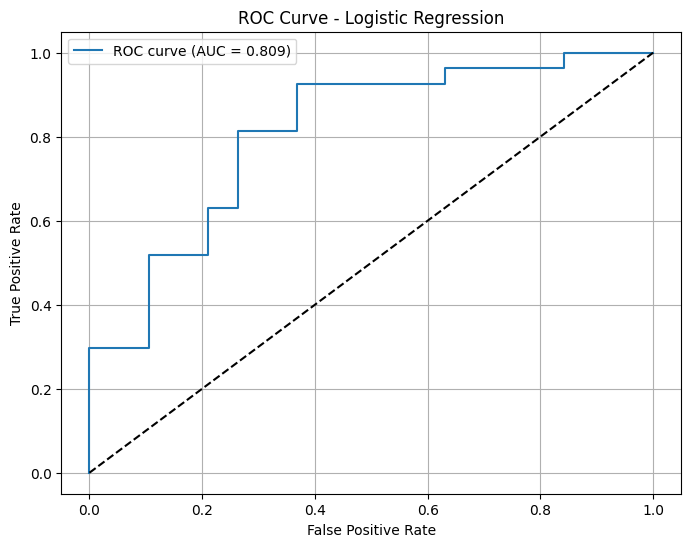

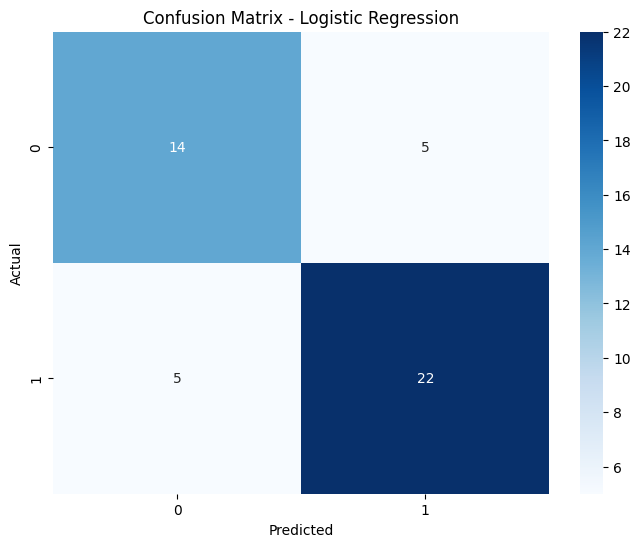

In [ ]:
X_test_with_const = sm.add_constant(X_test)  # Add constant to X_test
y_prob_test = final_results.predict(X_test_with_const) # Predict probabilities
y_pred_test = (y_prob_test >= 0.5).astype(int)  # Convert probabilities to predictions (0 or 1)



# Plot ROC curve
plt.figure(figsize=(8, 6))
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.grid(True)
plt.show()

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

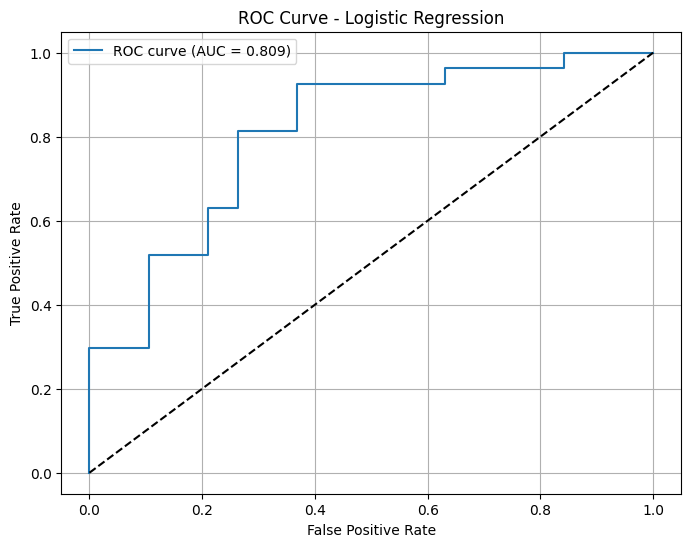

In [ ]:
plt.figure(figsize=(8, 6))
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.grid(True)
plt.show()

## Converting to tesnsors

In [ ]:
X_train_tensor = torch.FloatTensor(X_train.values)
y_train_tensor = torch.FloatTensor(y_train.values)
X_test_tensor = torch.FloatTensor(X_test.values)
y_test_tensor = torch.FloatTensor(y_test.values)
y_test_tensor_1 = y_test_tensor
print("Training set shape:", X_train_tensor.shape)
print("Test set shape:", X_test_tensor.shape)

Training set shape: torch.Size([137, 7])
Test set shape: torch.Size([46, 7])


## Define model of Bayesian Logistic Regression with non informative priors

In [ ]:
def model(X, y=None):

    num_features = X.shape[1]
    weights = pyro.sample('weights', dist.Normal(torch.zeros(num_features), 10 * torch.ones(num_features)))
    bias = pyro.sample('bias', dist.Normal(0., 10.))

    logits = X.mv(weights) + bias  # Use matrix-vector multiplication for efficiency

    # Likelihood
    with pyro.plate('data', X.shape[0]):
        pyro.sample('obs', dist.Bernoulli(logits=logits), obs=y)

    return logits

##  Run MCMC Sampling

In [ ]:
nuts_kernel = NUTS(model)
mcmc = MCMC(nuts_kernel, num_samples=1000, warmup_steps=200, num_chains=4)

# Run MCMC
print("Starting MCMC sampling...")
mcmc.run(X_train_tensor, y_train_tensor)
print("MCMC sampling completed!")

# Get samples
samples = mcmc.get_samples()

# Extract parameter estimates (now with 4 chains combined)
weight_samples = samples['weights'].detach().numpy()
bias_samples = samples['bias'].detach().numpy()

# Calculate posterior means
weight_means = weight_samples.mean(axis=0)
bias_mean = bias_samples.mean()

# Calculate 95% credible intervals
weight_ci = np.percentile(weight_samples, [2.5, 97.5], axis=0)
bias_ci = np.percentile(bias_samples, [2.5, 97.5])

# Print chain statistics


/usr/local/lib/python3.10/dist-packages/pyro/infer/mcmc/api.py:499: UserWarning: num_chains=4 is more than available_cpu=1. Chains will be drawn sequentially.
  warnings.warn(


Starting MCMC sampling...


Sample [3]: 100%|██████████| 1200/1200 [01:00, 19.71it/s, step size=2.41e-01, acc. prob=0.943]

MCMC sampling completed!


In [ ]:
mcmc.summary(prob=0.95)


                mean       std    median      2.5%     97.5%     n_eff     r_hat
      bias     -2.89      1.04     -2.83     -5.08     -1.01   1739.14      1.00
weights[0]      2.71      0.97      2.69      0.95      4.73   1827.04      1.00
weights[1]     -0.52      0.39     -0.50     -1.26      0.26   3143.78      1.00
weights[2]      1.76      0.86      1.73      0.06      3.44   2607.48      1.00
weights[3]      2.55      0.78      2.53      1.16      4.15   2424.48      1.00
weights[4]     -4.45      1.19     -4.40     -6.88     -2.33   2688.85      1.00
weights[5]     -2.10      0.72     -2.08     -3.55     -0.70   3647.33      1.00
weights[6]      2.66      0.80      2.63      1.10      4.21   2232.79      1.00

Number of divergences: 0


In [ ]:
def predict_proba(X, weight_samples, bias_samples):
    X = torch.tensor(X, dtype=torch.float32)
    logits = torch.matmul(X, torch.tensor(weight_samples.T, dtype=torch.float32)) \
             + torch.tensor(bias_samples, dtype=torch.float32)
    probs = torch.sigmoid(logits).numpy()
    return probs.mean(axis=1)

y_prob_bayes = predict_proba(X_test.values, weight_samples, bias_samples)
y_pred_bayes = (y_prob_bayes >= 0.5).astype(int) # Convert probabilities to class predictions (0 or 1)

# Calculate metrics
bayes_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_bayes),
    'Precision': precision_score(y_test, y_pred_bayes), # Use class predictions for precision
    'Recall': recall_score(y_test, y_pred_bayes),
    'F1-score': f1_score(y_test, y_pred_bayes),
    'ROC-AUC': roc_auc_score(y_test, y_prob_bayes) # ROC-AUC still uses probabilities
}

print("=== Bayesian Logistic Regression Results ===")
for metric, value in bayes_metrics.items():
    print(f"{metric}: {value:.3f}")


=== Bayesian Logistic Regression Results ===
Accuracy: 0.783
Precision: 0.815
Recall: 0.815
F1-score: 0.815
ROC-AUC: 0.807


In [ ]:
weight_samples_ninf = weight_samples
bias_samples_ninf = bias_samples

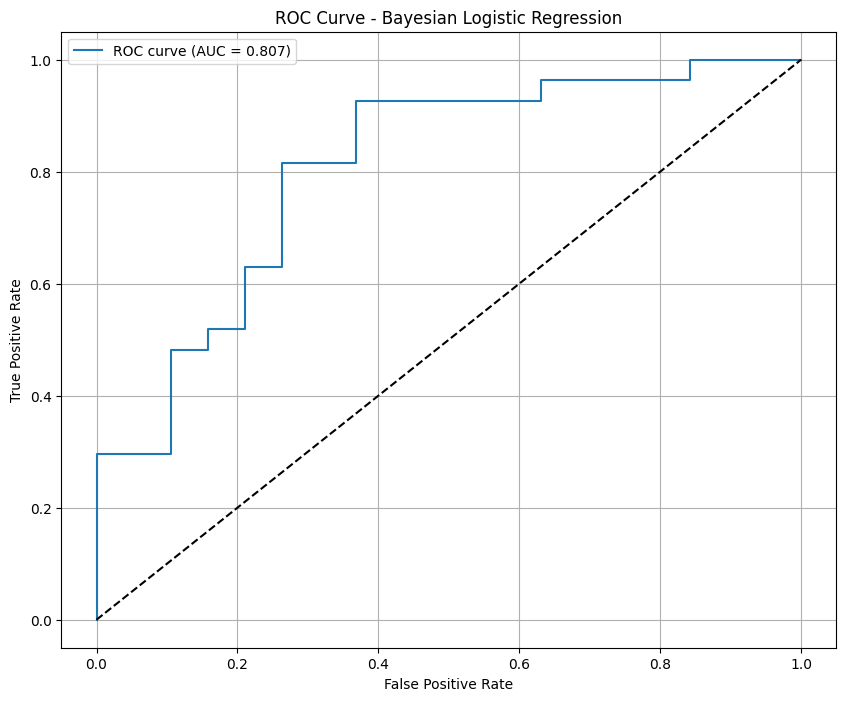

In [ ]:
plt.figure(figsize=(10, 8))  # Установите размер фигуры
fpr, tpr, _ = roc_curve(y_test, y_prob_bayes)
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Bayesian Logistic Regression')
plt.legend()
plt.grid(True)
plt.show()

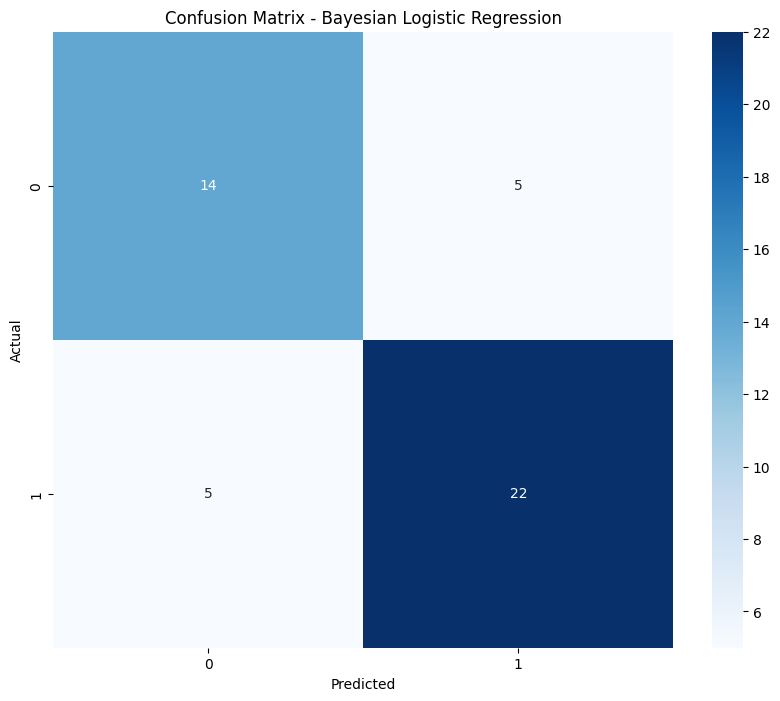

In [ ]:
plt.figure(figsize=(10, 8))  # Установите размер фигуры
y_pred_bayes_noninf = (y_prob_bayes >= 0.5).astype(int)
sns.heatmap(confusion_matrix(y_test, y_pred_bayes_noninf), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Bayesian Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


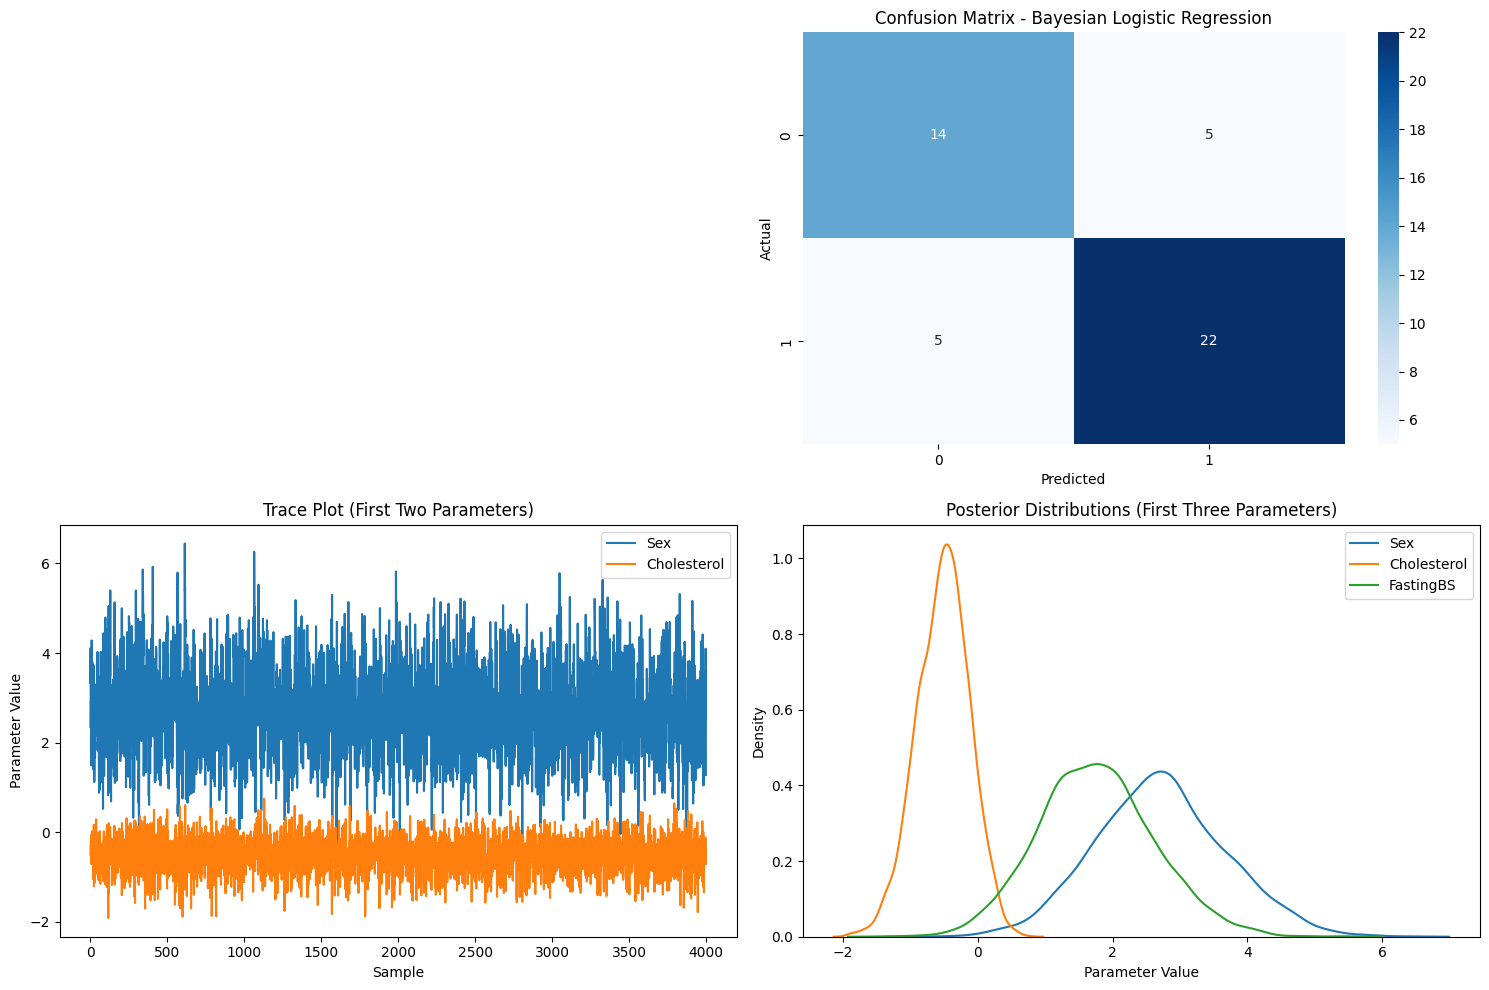

In [ ]:
# Create a figure with multiple subplots
y_prob_bayes_noninf = predict_proba(X_test.values, weight_samples, bias_samples)
plt.figure(figsize=(15, 10))

# 1. ROC Curve


# 2. Confusion Matrix
plt.subplot(2, 2, 2)
# Convert probabilities to class predictions before using in confusion_matrix
y_pred_bayes_noninf = (y_prob_bayes_noninf >= 0.5).astype(int)
sns.heatmap(confusion_matrix(y_test, y_pred_bayes_noninf), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Bayesian Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# 3. Trace Plot for first two parameters
plt.subplot(2, 2, 3)
plt.plot(weight_samples[:, 0], label=X_train.columns[0])
plt.plot(weight_samples[:, 1], label=X_train.columns[1])
plt.title('Trace Plot (First Two Parameters)')
plt.xlabel('Sample')
plt.ylabel('Parameter Value')
plt.legend()

# 4. Posterior Distributions
plt.subplot(2, 2, 4)
for i in range(min(3, len(X_train.columns))):
    sns.kdeplot(weight_samples[:, i], label=X_train.columns[i])
plt.title('Posterior Distributions (First Three Parameters)')
plt.xlabel('Parameter Value')
plt.ylabel('Density')
plt.legend()

plt.tight_layout()
plt.show()

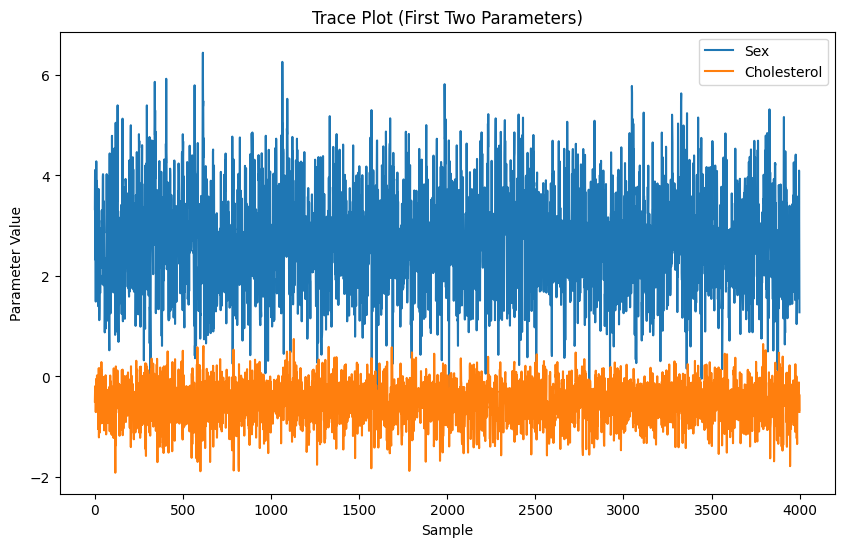

In [ ]:
plt.figure(figsize=(10, 6))  # Установите размер фигуры
plt.plot(weight_samples[:, 0], label=X_train.columns[0])
plt.plot(weight_samples[:, 1], label=X_train.columns[1])
plt.title('Trace Plot (First Two Parameters)')
plt.xlabel('Sample')
plt.ylabel('Parameter Value')
plt.legend()
plt.show()

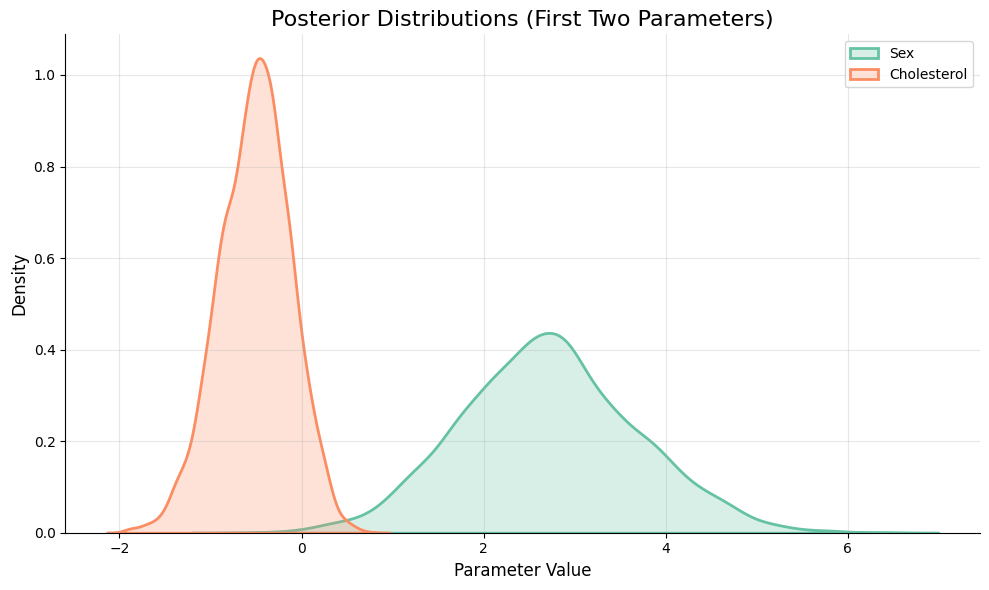

In [ ]:
plt.figure(figsize=(10, 6))

for i in range(min(2, len(X_train.columns))):
    sns.kdeplot(
        weight_samples[:, i],
        label=X_train.columns[i],
        fill=True,  # Fill the area under the curve
        linewidth=2, # Make lines thicker
        color=sns.color_palette("Set2")[i] # Use distinct colors from a palette
    )


plt.title('Posterior Distributions (First Two Parameters)', fontsize=16) # Increase title font size
plt.xlabel('Parameter Value', fontsize=12)  # Increase label font sizes
plt.ylabel('Density', fontsize=12)
plt.legend(fontsize=10)  # Adjust legend font size

plt.grid(True, alpha=0.3) # Add a subtle grid for better readability
sns.despine()  # Remove top and right spines for a cleaner look

plt.tight_layout()
plt.show()

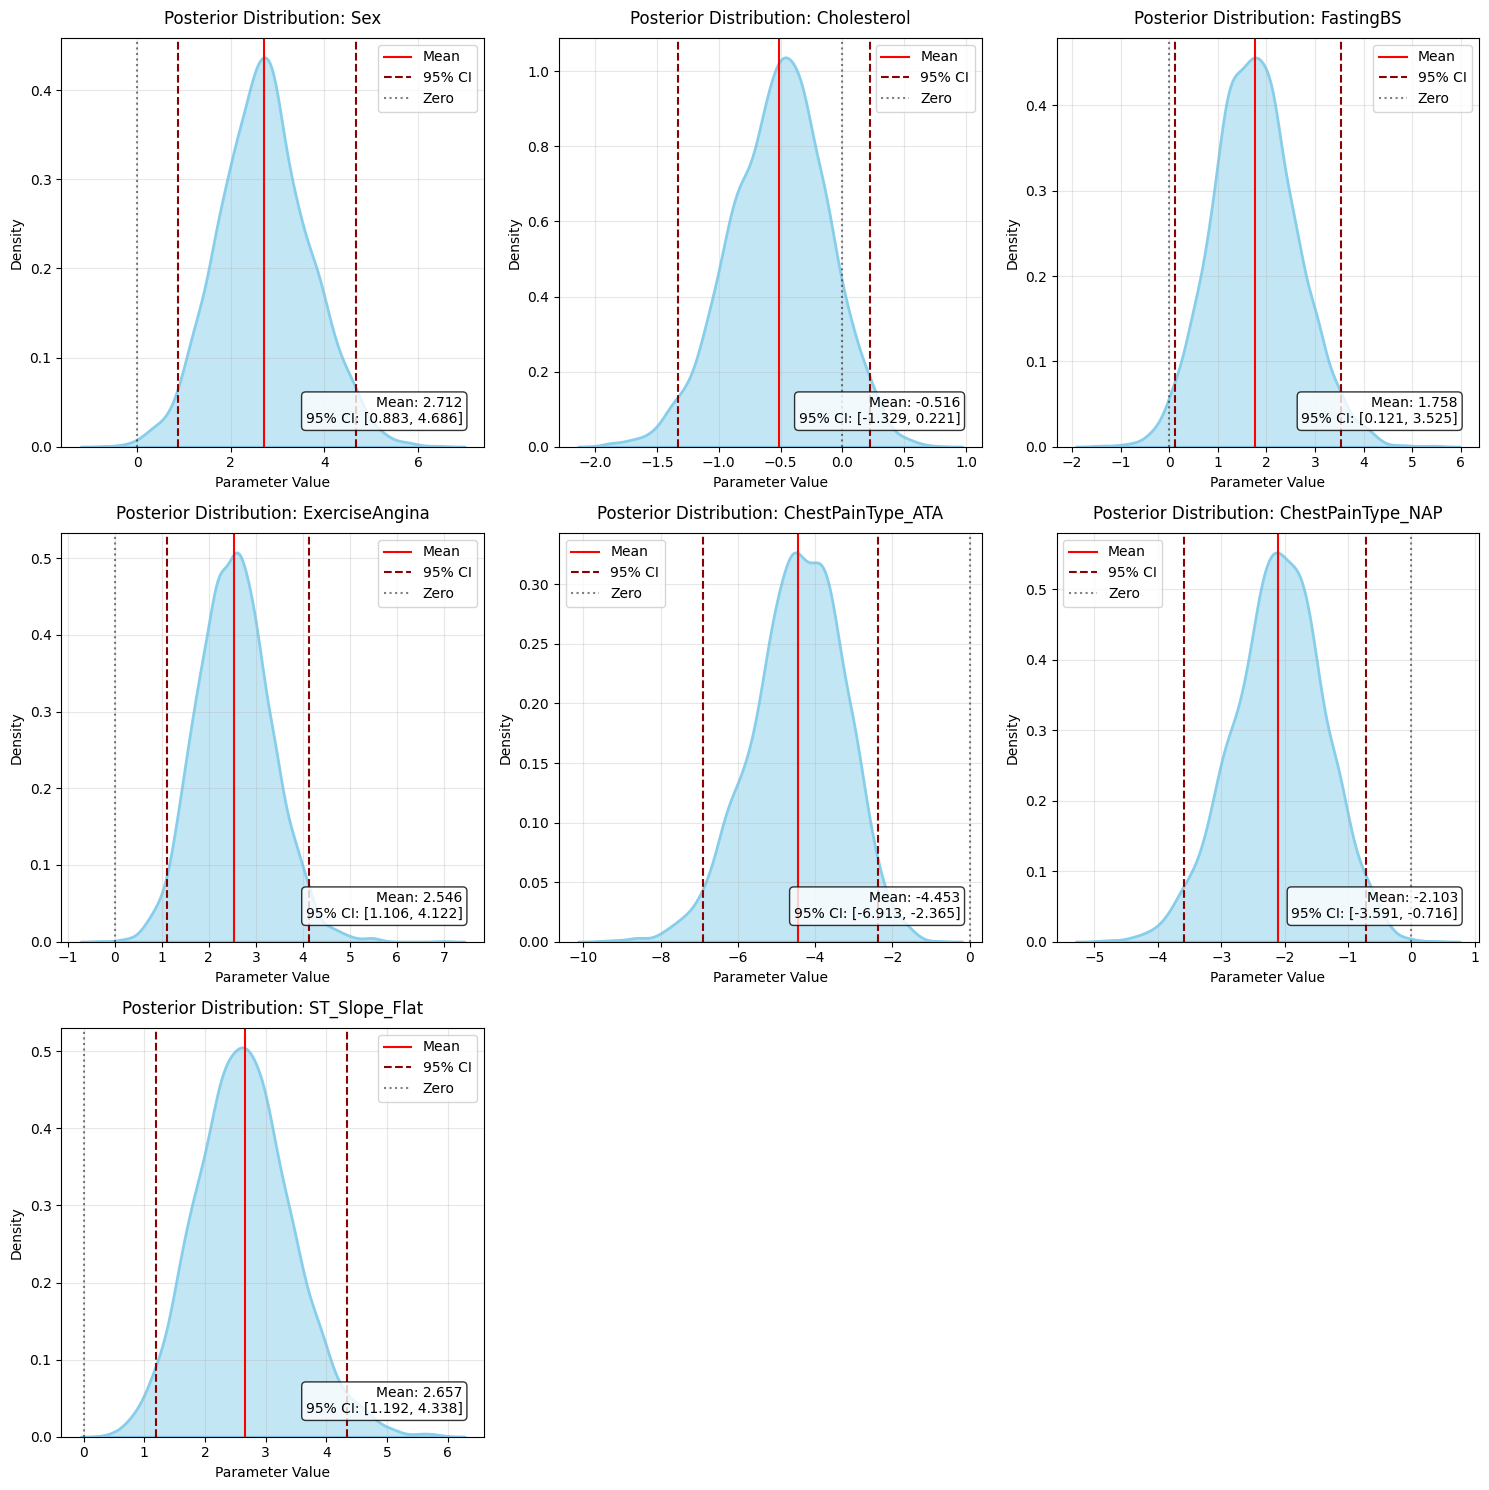

In [ ]:
n_features = len(X_train.columns)
n_cols = 3
n_rows = (n_features + n_cols - 1) // n_cols  # Ceiling division to get number of rows needed

plt.figure(figsize=(15, 5 * n_rows))

for i, feature in enumerate(X_train.columns):
    plt.subplot(n_rows, n_cols, i + 1)

    # Plot the density with a better style
    sns.kdeplot(
        data=weight_samples[:, i],
        fill=True,
        color='skyblue',
        alpha=0.5,
        linewidth=2
    )

    # Add vertical lines for mean and CI
    plt.axvline(weight_means[i], color='red', linestyle='-', label='Mean')
    plt.axvline(weight_ci[0][i], color='darkred', linestyle='--', label='95% CI')
    plt.axvline(weight_ci[1][i], color='darkred', linestyle='--')

    # Add zero line for reference
    plt.axvline(0, color='black', linestyle=':', alpha=0.5, label='Zero')

    plt.title(f'Posterior Distribution: {feature}', fontsize=12, pad=10)
    plt.xlabel('Parameter Value', fontsize=10)
    plt.ylabel('Density', fontsize=10)

    # Add mean and CI values in text box at the bottom
    text = f'Mean: {weight_means[i]:.3f}\n95% CI: [{weight_ci[0][i]:.3f}, {weight_ci[1][i]:.3f}]'
    plt.text(0.95, 0.05, text,  # Changed vertical alignment to 'bottom'
             transform=plt.gca().transAxes,
             verticalalignment='bottom',  # Align text to the bottom
             horizontalalignment='right',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
table1.round(2)

,№,Metrics,Value
0,1,Accuracy,0.78
1,2,Precision,0.81
2,3,Recall,0.81
3,4,F1-score,0.81
4,5,ROC-AUC,0.81


In [ ]:
bayes_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_bayes),
    'Precision': precision_score(y_test, y_pred_bayes),
    'Recall': recall_score(y_test, y_pred_bayes),
    'F1-score': f1_score(y_test, y_pred_bayes),
    'ROC-AUC': roc_auc_score(y_test, y_prob_bayes)
}

# Create the DataFrame
table2 = pd.DataFrame(bayes_metrics, index=['Bayesian Logistic Regression'])
table2 = table2.T  # Transpose to have metrics as rows

# Change the index to a RangeIndex starting from 1
table2.index = pd.RangeIndex(start=1, stop=len(table2.index) + 1)

table2 = table2.rename_axis("№").reset_index()  # Rename index to "№" and make it a column

# Display the table
table2.round(2)

,№,Bayesian Logistic Regression
0,1,0.78
1,2,0.81
2,3,0.81
3,4,0.81
4,5,0.81


In [ ]:
Metrics	Bayesian Log Regression non informative  Bayesian Log Regression informative
Accuracy	0.78 0.83
Precision	0.81 0.76
Recall	0.81 0.96
F1-score	0.81 0.85
ROC-AUC	0.81 0.93

SyntaxError: invalid syntax (<ipython-input-26-ea4c463cb93b>, line 1)